# 2. Import Libraries

This section imports the Python libraries required for data analysis,
data visualization, and logistics business analysis.

# 1. Business Understanding

## Client

The client is a logistics company that manages orders, shipments,
warehouses, transportation, delivery partners, and customer deliveries.

The company has operational logistics data but needs a clear analytical
view of its delivery performance, delays, routes, warehouse operations,
transportation costs, and delivery partner performance.

## Business Problem

The logistics company has operational data but does not have a clear
analytical view of delivery performance, delays, route efficiency,
warehouse operations, transportation costs, and delivery partner
performance.

Management needs a reliable analytics solution to understand operational
performance and support data-supported decisions.

## Objectives

The main objectives of this project are:

1. Measure delivery performance.
2. Identify delayed shipments.
3. Understand delay patterns.
4. Analyze delivery routes.
5. Compare warehouse performance.
6. Analyze transportation modes.
7. Analyze delivery partners.
8. Understand logistics costs.
9. Monitor customer experience indicators.
10. Support data-supported operational decisions.

## Business Questions

The analysis will answer questions related to:

- Total orders and delivered orders
- Delayed orders and on-time delivery percentage
- Average delivery time and average delay
- Route shipment volume, delays, costs, and cost per kilometer
- Warehouse order volume, processing time, and delays
- Shipping mode usage, cost, delivery time, and delays
- Delivery partner shipment volume, on-time performance, cost, and damage rate
- Total and average logistics costs
- Fuel and shipping costs
- Customer ratings
- Returns and damaged shipments

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

project_root = next(
    directory
    for base in (Path.cwd(), *Path.cwd().parents)
    for directory in (base / "logistics_delivery_analytics", base)
    if (directory / "src" / "data_loader.py").is_file()
 )
sys.path.insert(0, str(project_root.parent))
from logistics_delivery_analytics.src.data_loader import load_data
from logistics_delivery_analytics.src.data_cleaner import clean_data
from logistics_delivery_analytics.src.business_analysis import (
    calculate_total_orders,
    calculate_total_delivered,
    calculate_total_delayed,
    calculate_on_time_percentage,
    calculate_average_delivery_days,
    calculate_average_delay_days,
    calculate_total_shipping_cost,
    calculate_average_shipping_cost,
    calculate_total_fuel_cost,
    calculate_total_logistics_cost,
    calculate_average_logistics_cost,
    calculate_average_cost_per_km,
    calculate_average_customer_rating,
    calculate_return_rate,
    calculate_damage_rate,
 )
from logistics_delivery_analytics.src.visualization import (
    plot_delivery_status,
    plot_monthly_orders,
    plot_monthly_delivery_performance,
    plot_delay_by_warehouse,
    plot_delay_by_shipping_mode,
    plot_delay_by_route,
    plot_delay_distribution,
    plot_cost_by_shipping_mode,
    plot_cost_by_route,
    plot_cost_trend,
    plot_orders_by_warehouse,
    plot_processing_time_by_warehouse,
    plot_shipments_by_partner,
    plot_partner_delivery_performance,
    plot_partner_cost,
    plot_customer_rating_distribution,
    plot_rating_by_delivery_status,
 )

# 3. Load Data

This section loads the raw logistics dataset using the standardized
load_data() function.

The raw dataset is preserved and is not directly modified.

In [6]:
raw_path = str(project_root / "data" / "raw" / "logistics_data.csv")

df = load_data(raw_path)

print("Raw data loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Raw data loaded successfully!
Rows: 5000
Columns: 22


# 4. Basic Data Understanding

This section provides an initial understanding of the logistics dataset.

The dataset structure, rows, columns, data types, numerical summary,
and sample records are examined before performing data cleaning.

In [7]:
df.shape

(5000, 22)

In [8]:
df.head()

,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,...,shipping_cost,fuel_cost,warehouse_processing_hours,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag
0,ORD101253,CUST12780,2025-03-12,Bengaluru,Bengaluru,Chennai,451.7,Home & Kitchen,7,5.51,...,2044.56,381.66,8.36,2025-03-14,2025-03-19,2025-03-24,Delayed,3.0,No,No
1,ORD102838,CUST11842,2025-12-02,Delhi,Delhi,Surat,592.8,Automotive,1,1.05,...,2582.70,385.02,10.33,2025-12-05,2025-12-12,2025-12-12,Delivered,4.0,No,No
2,ORD103457,CUST10940,2025-04-21,Pune,Pune,Nagpur,191.9,Clothing,3,9.09,...,817.23,185.83,8.88,2025-04-23,2025-04-28,2025-04-28,Delivered,5.0,No,No
3,ORD100061,CUST10263,2025-02-21,Pune,Pune,Coimbatore,376.4,Clothing,7,1.34,...,1713.22,386.35,10.18,2025-02-24,2025-03-02,2025-03-04,Delayed,3.0,No,No
4,ORD103947,CUST12467,2025-08-22,Mumbai,Mumbai,Delhi,895.3,Sports,5,3.95,...,3980.06,990.42,11.17,2025-08-24,2025-08-30,2025-08-30,Delivered,4.0,No,No


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    5000 non-null   object 
 1   customer_id                 5000 non-null   object 
 2   order_date                  5000 non-null   object 
 3   warehouse                   5000 non-null   object 
 4   origin_city                 5000 non-null   object 
 5   destination_city            4960 non-null   object 
 6   distance_km                 5000 non-null   float64
 7   product_category            5000 non-null   object 
 8   quantity                    5000 non-null   int64  
 9   weight_kg                   5000 non-null   float64
 10  shipping_mode               5000 non-null   object 
 11  delivery_partner            5000 non-null   object 
 12  shipping_cost               4950 non-null   float64
 13  fuel_cost                   4950 

In [10]:
df.describe()

,distance_km,quantity,weight_kg,shipping_cost,fuel_cost,warehouse_processing_hours,customer_rating
count,5000.000000,5000.000000,5000.000000,4950.000000,4950.000000,4941.000000,4911.000000
mean,411.098620,3.967000,5.528694,2286.791669,373.230737,8.391716,4.124822
std,260.537306,2.009955,3.921885,1682.276034,246.607318,2.306332,0.711340
min,-25.000000,0.000000,0.200000,-100.000000,20.000000,2.000000,2.000000
25%,221.775000,2.000000,2.700000,1141.012500,194.930000,6.810000,4.000000
50%,354.350000,4.000000,4.640000,1808.200000,319.115000,8.380000,4.000000
75%,541.800000,6.000000,7.422500,2906.355000,497.037500,10.020000,5.000000
max,1800.000000,7.000000,34.090000,16275.330000,1755.710000,15.650000,5.000000


In [11]:
df.columns

Index(['order_id', 'customer_id', 'order_date', 'warehouse', 'origin_city',
       'destination_city', 'distance_km', 'product_category', 'quantity',
       'weight_kg', 'shipping_mode', 'delivery_partner', 'shipping_cost',
       'fuel_cost', 'warehouse_processing_hours', 'dispatch_date',
       'expected_delivery_date', 'actual_delivery_date', 'delivery_status',
       'customer_rating', 'damage_flag', 'return_flag'],
      dtype='object')

In [12]:
df.dtypes

order_id                       object
customer_id                    object
order_date                     object
warehouse                      object
origin_city                    object
destination_city               object
distance_km                   float64
product_category               object
quantity                        int64
weight_kg                     float64
shipping_mode                  object
delivery_partner               object
shipping_cost                 float64
fuel_cost                     float64
warehouse_processing_hours    float64
dispatch_date                  object
expected_delivery_date         object
actual_delivery_date           object
delivery_status                object
customer_rating               float64
damage_flag                    object
return_flag                    object
dtype: object

# 5. Data Quality

This section checks the quality of the raw logistics dataset before
cleaning.

The analysis checks missing values, duplicate records, unique values,
data types, and invalid business values.

In [13]:
df.isnull().sum()

order_id                       0
customer_id                    0
order_date                     0
warehouse                      0
origin_city                    0
destination_city              40
distance_km                    0
product_category               0
quantity                       0
weight_kg                      0
shipping_mode                  0
delivery_partner               0
shipping_cost                 50
fuel_cost                     50
warehouse_processing_hours    59
dispatch_date                  0
expected_delivery_date         0
actual_delivery_date           0
delivery_status                0
customer_rating               89
damage_flag                    0
return_flag                    0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(25)

In [15]:
df.nunique()

order_id                      4975
customer_id                   2328
order_date                     365
warehouse                       12
origin_city                      6
destination_city                18
distance_km                   3677
product_category                16
quantity                         8
weight_kg                     1355
shipping_mode                    8
delivery_partner                12
shipping_cost                 4889
fuel_cost                     4727
warehouse_processing_hours    1027
dispatch_date                  367
expected_delivery_date         371
actual_delivery_date           374
delivery_status                  2
customer_rating                  4
damage_flag                      2
return_flag                      2
dtype: int64

In [16]:
print("Delivery Status:")
print(df["delivery_status"].unique())

print("\nShipping Mode:")
print(df["shipping_mode"].unique())

print("\nWarehouse:")
print(df["warehouse"].unique())

print("\nDelivery Partner:")
print(df["delivery_partner"].unique())

Delivery Status:
['Delayed' 'Delivered']

Shipping Mode:
['Road' 'Rail' 'Air' 'Express' 'road' 'air' 'express' 'rail']

Warehouse:
['Bengaluru' 'Delhi' 'Pune' 'Mumbai' 'Chennai' 'Hyderabad' 'pune'
 'bengaluru' 'hyderabad' 'mumbai' 'chennai' 'delhi']

Delivery Partner:
['DTDC' 'Delhivery' 'Shadowfax' 'Blue Dart' 'XpressBees' 'Ecom Express'
 'ecom express' 'blue dart' 'xpressbees' 'shadowfax' 'delhivery' 'dtdc']


In [17]:
print("Negative distance:", (df["distance_km"] < 0).sum())
print("Negative quantity:", (df["quantity"] < 0).sum())
print("Negative weight:", (df["weight_kg"] < 0).sum())
print("Negative shipping cost:", (df["shipping_cost"] < 0).sum())
print("Negative fuel cost:", (df["fuel_cost"] < 0).sum())
print(
    "Invalid customer ratings:",
    ((df["customer_rating"] < 0) |
     (df["customer_rating"] > 5)).sum()
)

Negative distance: 4
Negative quantity: 0
Negative weight: 0
Negative shipping cost: 4
Negative fuel cost: 0
Invalid customer ratings: 0


# 6. Data Cleaning

The raw logistics data is cleaned using the standardized data cleaning
functions defined for the project.

The cleaning process handles missing values, duplicate records, text
values, date columns, numeric columns, and business rules.

The cleaned dataset is used for further analysis while the original
raw dataset remains unchanged.

In [20]:
cleaned_df = clean_data(df)

print("Data cleaning completed!")
print("Original rows:", df.shape[0])
print("Cleaned rows:", cleaned_df.shape[0])
print("Original columns:", df.shape[1])
print("Cleaned columns:", cleaned_df.shape[1])

Data cleaning completed!
Original rows: 5000
Cleaned rows: 4975
Original columns: 22
Cleaned columns: 27


# 7. Derived Columns

The following business metrics are created from the cleaned logistics
data:

- delivery_days
- delay_days
- cost_per_km
- total_logistics_cost
- on_time_flag

These metrics are used throughout the KPI analysis and business analysis.

In [21]:
derived_columns = [
    "delivery_days",
    "delay_days",
    "cost_per_km",
    "total_logistics_cost",
    "on_time_flag"
]

cleaned_df[derived_columns].head()

,delivery_days,delay_days,cost_per_km,total_logistics_cost,on_time_flag
0,10,5,4.526367,2426.22,0
1,7,0,4.356781,2967.72,1
2,5,0,4.258624,1003.06,1
3,8,2,4.551594,2099.57,0
4,6,0,4.445504,4970.48,1


# 8. EDA

Exploratory Data Analysis is performed at three levels:

1. Univariate Analysis
2. Bivariate Analysis
3. Multivariate Analysis

The purpose is to understand the distribution of logistics variables
and relationships between delivery, cost, route, warehouse, shipping
mode, and partner-related variables.

## 8.1 Univariate Analysis

Univariate analysis examines individual variables to understand their
distribution and frequency.

In [22]:
cleaned_df["distance_km"].describe()

count    4975.000000
mean      411.187276
std       260.196345
min        28.800000
25%       221.900000
50%       354.200000
75%       541.800000
max      1800.000000
Name: distance_km, dtype: float64

In [23]:
cleaned_df["shipping_cost"].describe()

count     4975.000000
mean      2281.061371
std       1671.922649
min        121.540000
25%       1147.115000
50%       1808.200000
75%       2891.865000
max      16275.330000
Name: shipping_cost, dtype: float64

In [24]:
cleaned_df["customer_rating"].describe()

count    4975.000000
mean        4.122412
std         0.705606
min         2.000000
25%         4.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: customer_rating, dtype: float64

In [25]:
cleaned_df["delivery_status"].value_counts()

delivery_status
Delivered    3786
Delayed      1189
Name: count, dtype: int64

In [26]:
cleaned_df["shipping_mode"].value_counts()

shipping_mode
Road       2499
Rail        925
Air         904
Express     607
road         22
air           7
rail          6
express       5
Name: count, dtype: int64

In [27]:
cleaned_df["warehouse"].value_counts()

warehouse
Hyderabad    1078
Bengaluru     882
Pune          782
Chennai       758
Mumbai        734
Delhi         701
pune            9
hyderabad       9
chennai         7
mumbai          6
bengaluru       5
delhi           4
Name: count, dtype: int64

## 8.2 Bivariate Analysis

Bivariate analysis examines relationships between two variables.

The analysis focuses on relationships such as distance and delivery time,
distance and shipping cost, warehouse and delay, shipping mode and cost,
and delivery status and customer rating.

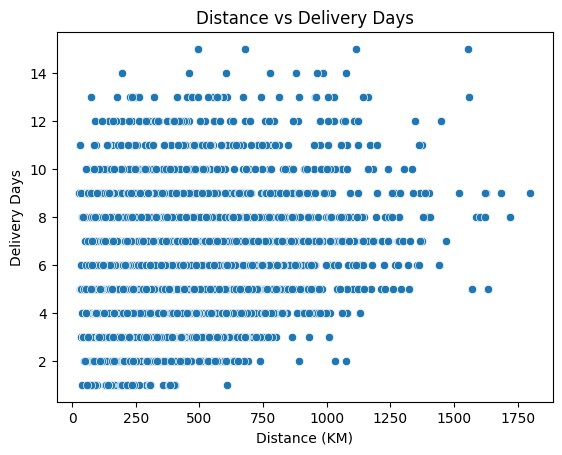

In [28]:
sns.scatterplot(
    data=cleaned_df,
    x="distance_km",
    y="delivery_days"
)

plt.title("Distance vs Delivery Days")
plt.xlabel("Distance (KM)")
plt.ylabel("Delivery Days")
plt.show()

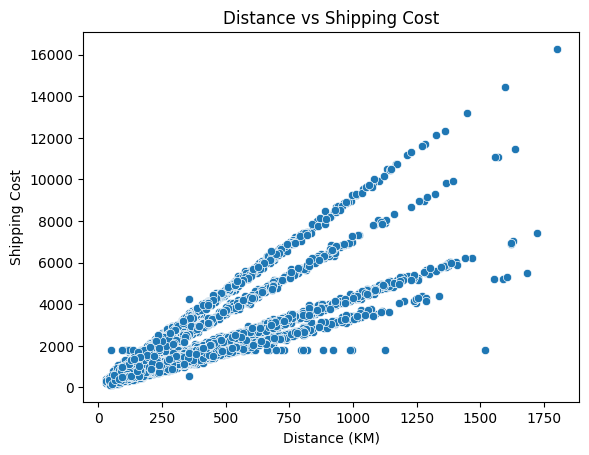

In [29]:
sns.scatterplot(
    data=cleaned_df,
    x="distance_km",
    y="shipping_cost"
)

plt.title("Distance vs Shipping Cost")
plt.xlabel("Distance (KM)")
plt.ylabel("Shipping Cost")
plt.show()

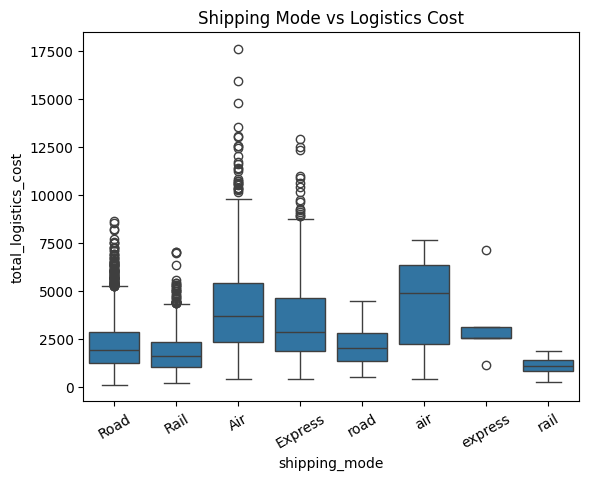

In [30]:
sns.boxplot(
    data=cleaned_df,
    x="shipping_mode",
    y="total_logistics_cost"
)

plt.title("Shipping Mode vs Logistics Cost")
plt.xticks(rotation=30)
plt.show()

## 8.3 Multivariate Analysis

Multivariate analysis examines relationships involving multiple
variables to provide a broader view of logistics operations.

Examples include warehouse and shipping mode with delivery delay,
partner and cost with delivery status, and route with cost and
delivery time.

In [31]:
correlation = cleaned_df.corr(numeric_only=True)

correlation

,distance_km,quantity,weight_kg,shipping_cost,fuel_cost,warehouse_processing_hours,customer_rating,damage_flag,return_flag,delivery_days,delay_days,cost_per_km,total_logistics_cost,on_time_flag
distance_km,1.000000,0.027918,-0.012677,0.793906,0.945049,0.007433,-0.008487,-0.012799,-0.007326,0.295795,0.056800,-0.156765,0.837153,-0.054705
quantity,0.027918,1.000000,-0.008524,0.022858,0.026289,0.011469,-0.018148,0.004186,-0.008296,0.027181,0.018782,0.012114,0.023982,-0.030548
weight_kg,-0.012677,-0.008524,1.000000,0.006975,-0.008881,-0.001349,0.011697,-0.009358,0.009394,-0.000769,-0.015463,0.082826,0.005092,0.013185
shipping_cost,0.793906,0.022858,0.006975,1.000000,0.747631,0.008102,0.018864,-0.014708,-0.011114,-0.051186,0.014415,0.359650,0.996168,-0.002948
fuel_cost,0.945049,0.026289,-0.008881,0.747631,1.000000,0.007617,-0.009934,-0.006454,-0.010783,0.281287,0.052541,-0.151935,0.802848,-0.049329
warehouse_processing_hours,0.007433,0.011469,-0.001349,0.008102,0.007617,1.000000,-0.013440,-0.010081,-0.018652,0.001548,0.003374,-0.004199,0.008276,-0.006620
customer_rating,-0.008487,-0.018148,0.011697,0.018864,-0.009934,-0.013440,1.000000,-0.034873,-0.016130,-0.306598,-0.419161,0.051661,0.015627,0.512082
damage_flag,-0.012799,0.004186,-0.009358,-0.014708,-0.006454,-0.010081,-0.034873,1.000000,0.081597,0.055294,0.061700,-0.006159,-0.014054,-0.076600
return_flag,-0.007326,-0.008296,0.009394,-0.011114,-0.010783,-0.018652,-0.016130,0.081597,1.000000,0.016280,0.013198,-0.011171,-0.011397,-0.014165
delivery_days,0.295795,0.027181,-0.000769,-0.051186,0.281287,0.001548,-0.306598,0.055294,0.016280,1.000000,0.712442,-0.559473,-0.008908,-0.610868


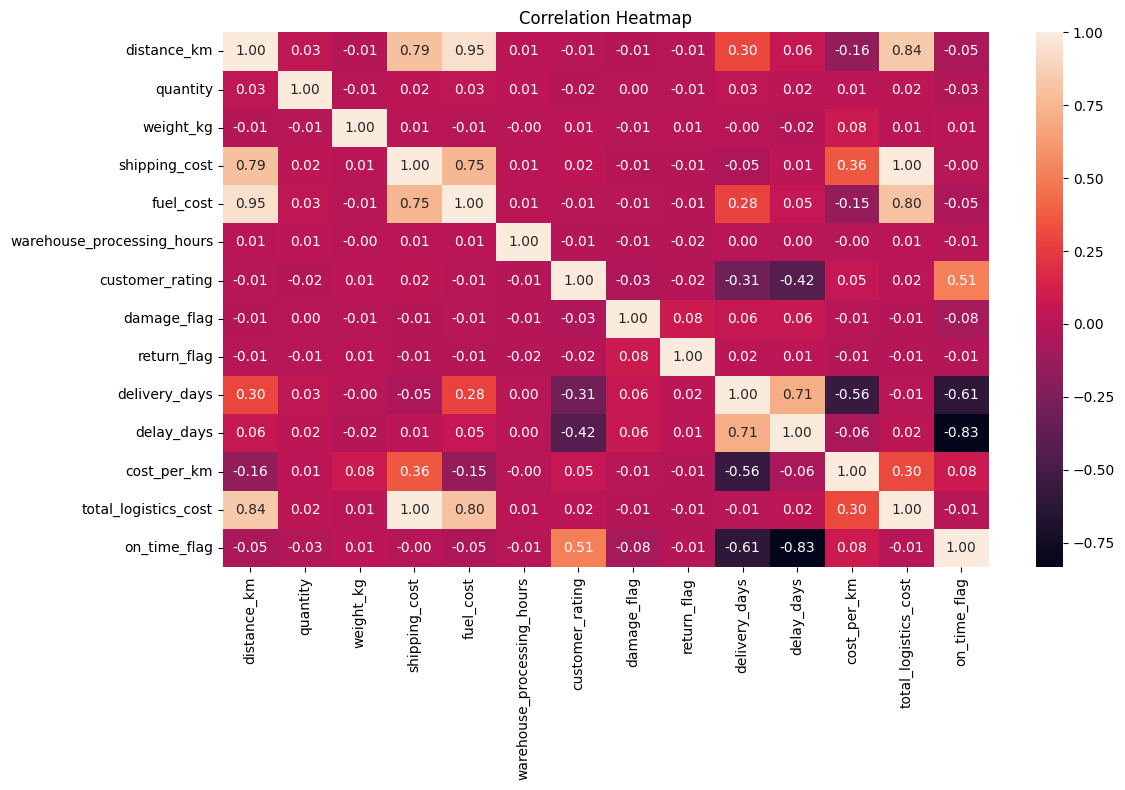

In [32]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 9. KPI Analysis

Key Performance Indicators are calculated to measure logistics delivery
performance, delivery delays, transportation costs, customer experience,
returns, and shipment damage.

The KPI results provide a high-level summary of operational performance.

In [35]:
print("Total Orders:", calculate_total_orders(cleaned_df))
print("Total Delivered:", calculate_total_delivered(cleaned_df))
print("Total Delayed:", calculate_total_delayed(cleaned_df))

print(
    "On-Time Delivery Percentage:",
    round(calculate_on_time_percentage(cleaned_df), 2),
    "%"
)

print(
    "Average Delivery Days:",
    round(calculate_average_delivery_days(cleaned_df), 2)
)

print(
    "Average Delay Days:",
    round(calculate_average_delay_days(cleaned_df), 2)
)

print(
    "Total Shipping Cost:",
    round(calculate_total_shipping_cost(cleaned_df), 2)
)

print(
    "Average Shipping Cost:",
    round(calculate_average_shipping_cost(cleaned_df), 2)
)

print(
    "Total Fuel Cost:",
    round(calculate_total_fuel_cost(cleaned_df), 2)
)

print(
    "Total Logistics Cost:",
    round(calculate_total_logistics_cost(cleaned_df), 2)
)

print(
    "Average Logistics Cost:",
    round(calculate_average_logistics_cost(cleaned_df), 2)
)

print(
    "Average Cost per KM:",
    round(calculate_average_cost_per_km(cleaned_df), 2)
)

print(
    "Average Customer Rating:",
    round(calculate_average_customer_rating(cleaned_df), 2)
)

print(
    "Return Rate:",
    round(calculate_return_rate(cleaned_df), 2),
    "%"
)

print(
    "Damage Rate:",
    round(calculate_damage_rate(cleaned_df), 2),
    "%"
)

Total Orders: 4975
Total Delivered: 3786
Total Delayed: 1189
On-Time Delivery Percentage: 76.1 %
Average Delivery Days: 5.63
Average Delay Days: 2.95
Total Shipping Cost: 11348280.32
Average Shipping Cost: 2281.06
Total Fuel Cost: 1852987.35
Total Logistics Cost: 13201267.67
Average Logistics Cost: 2653.52
Average Cost per KM: 5.77
Average Customer Rating: 4.12
Return Rate: 4.36 %
Damage Rate: 2.85 %


# 10. Business Analysis

This section answers the business questions defined in the project
requirements.

Each business question follows the required analytical approach:

Question → Data → Calculation → Visualization → Finding →
Business Meaning → Recommendation.


# 11. Visualization

This section presents visualizations that support the business analysis.

The charts are organized into delivery performance, delays, costs,
warehouse operations, delivery partners, and customer experience.

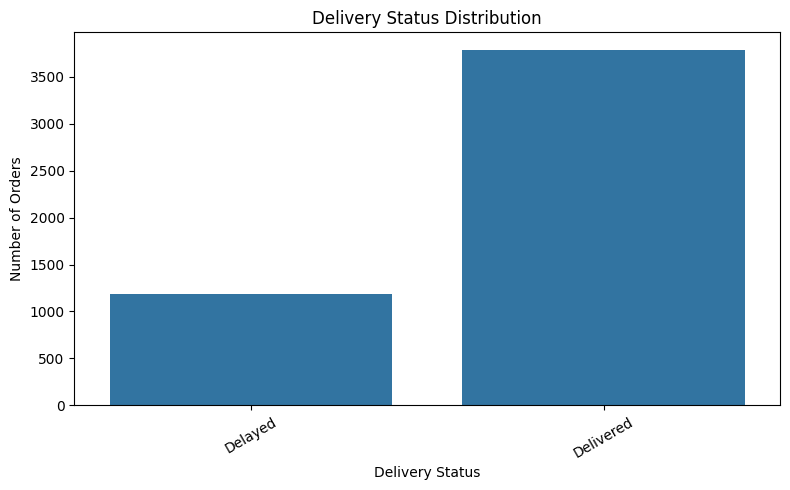

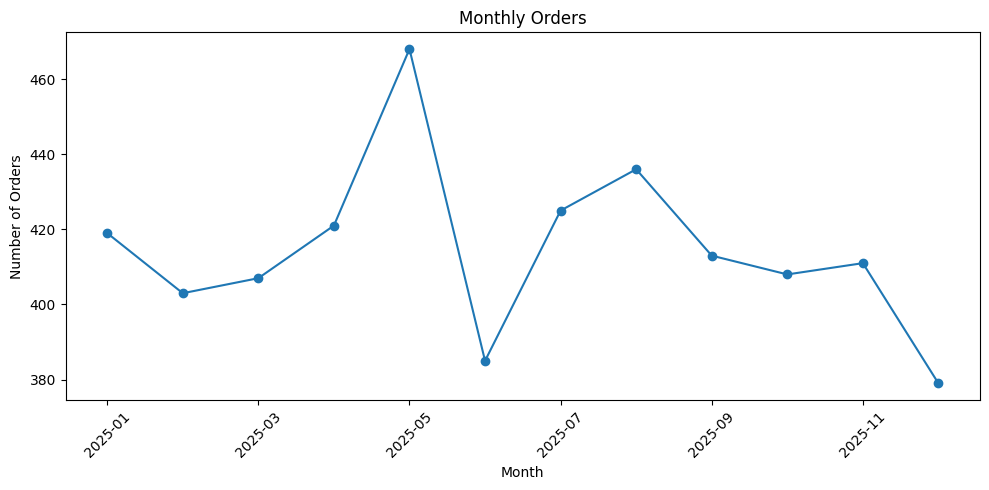

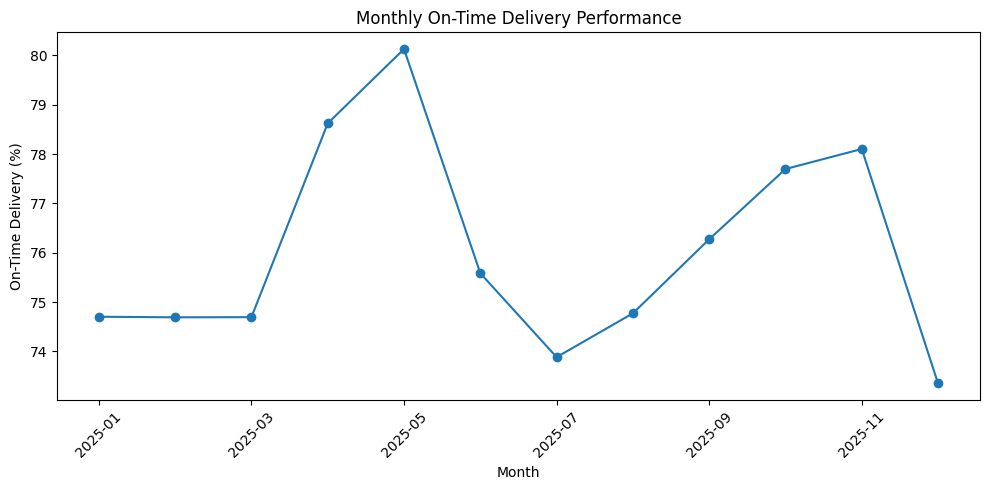

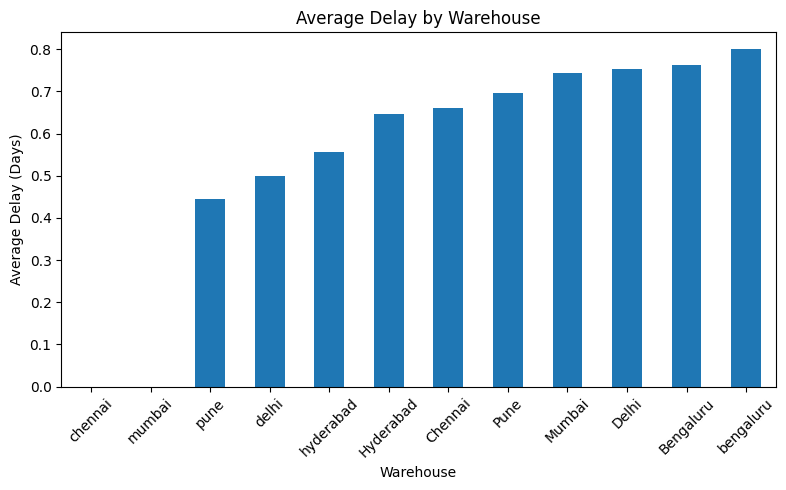

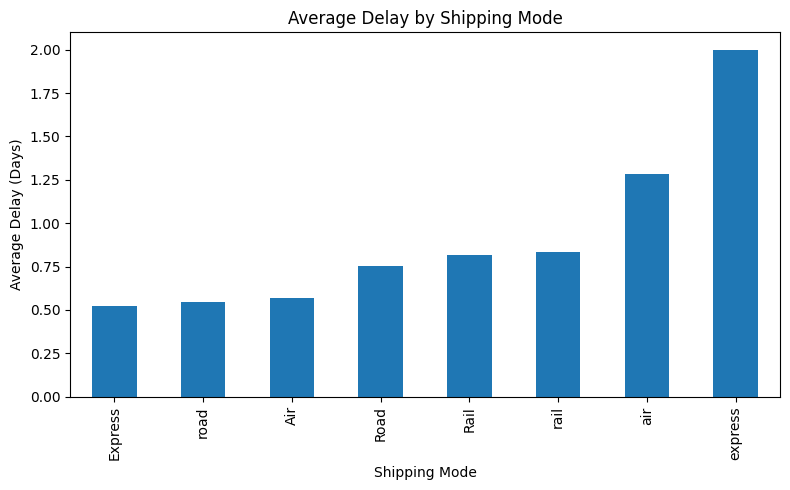

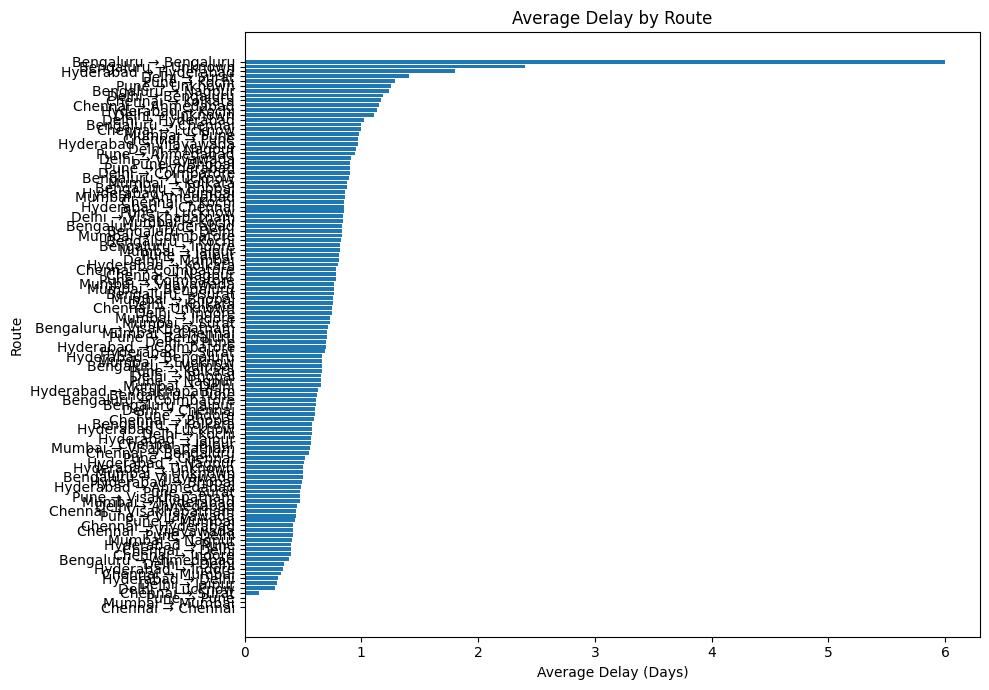

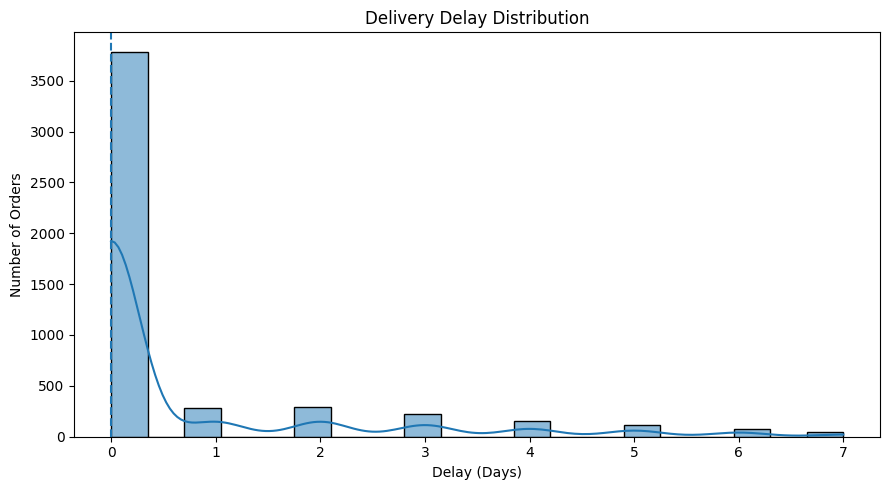

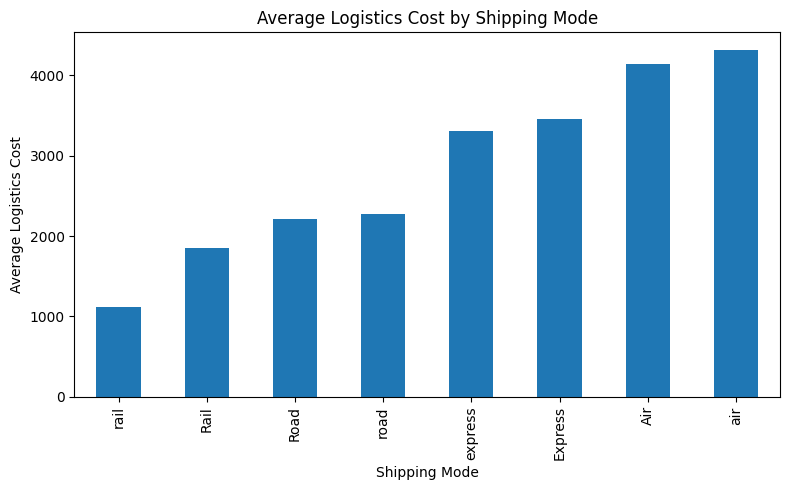

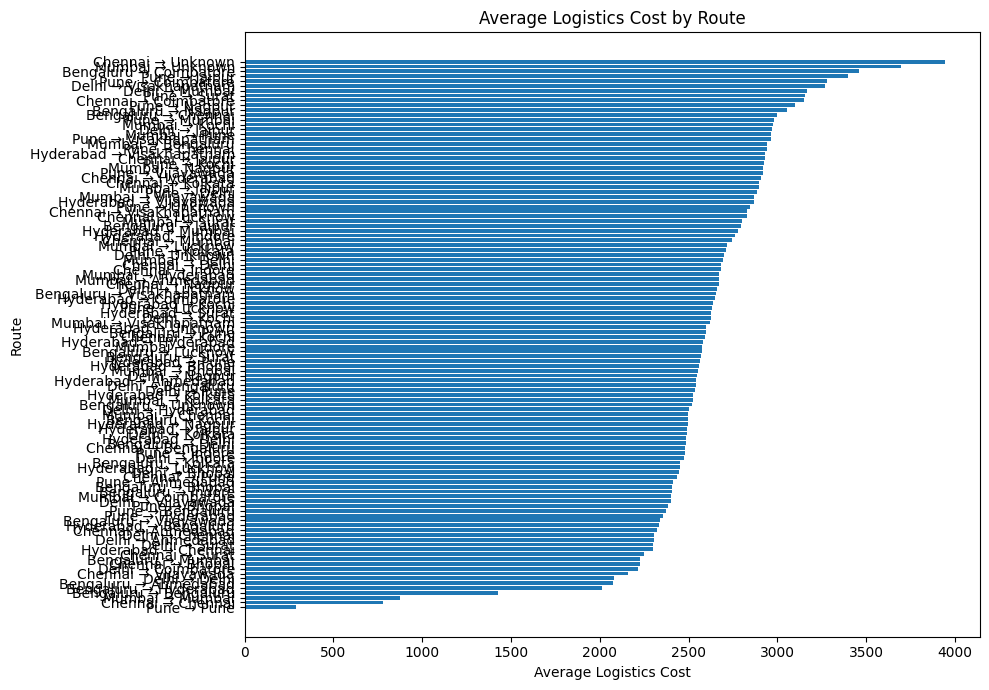

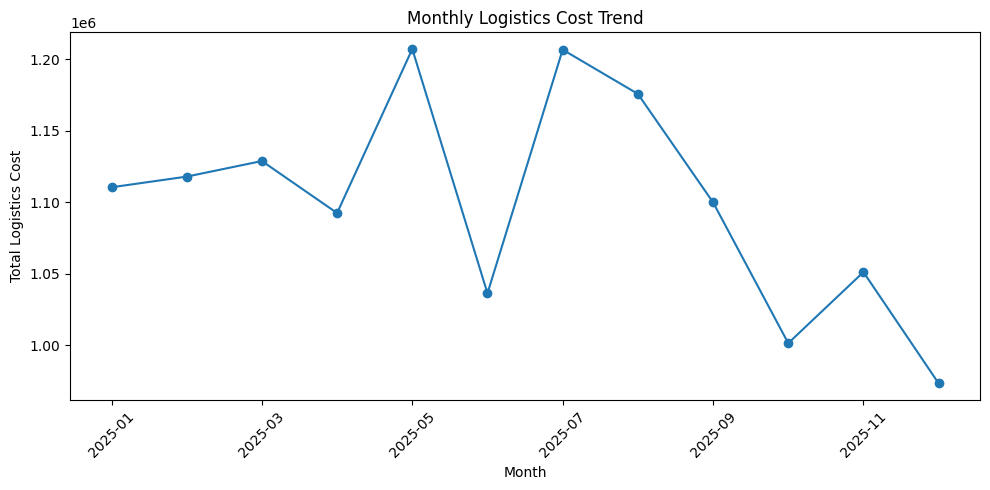

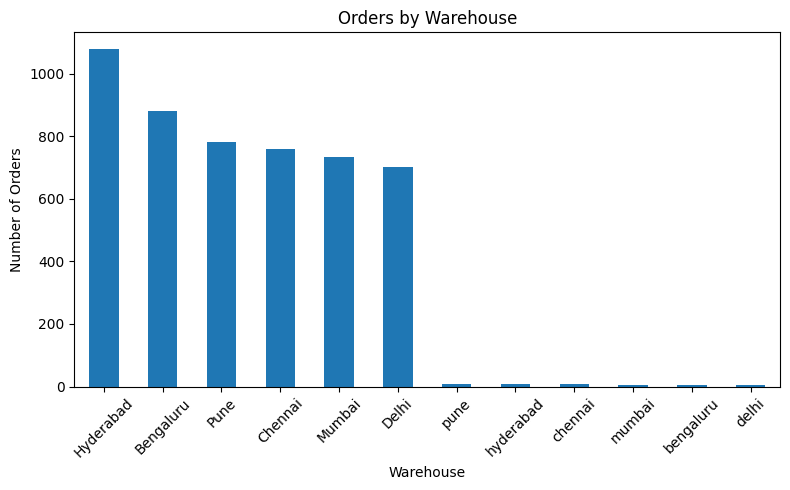

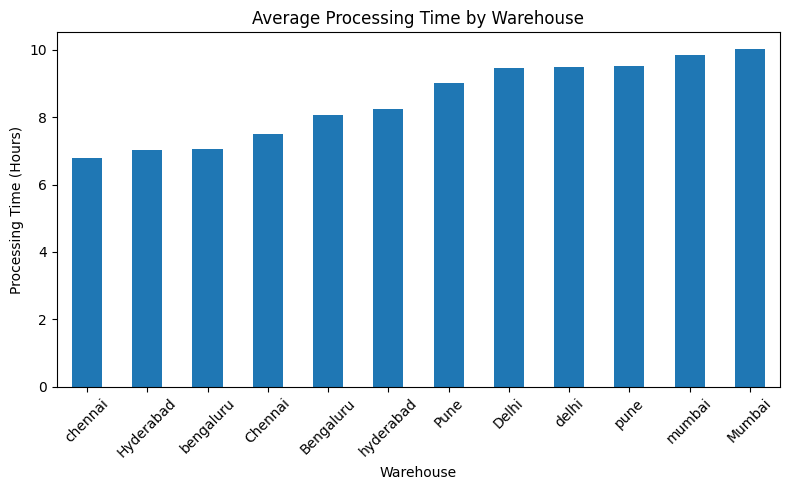

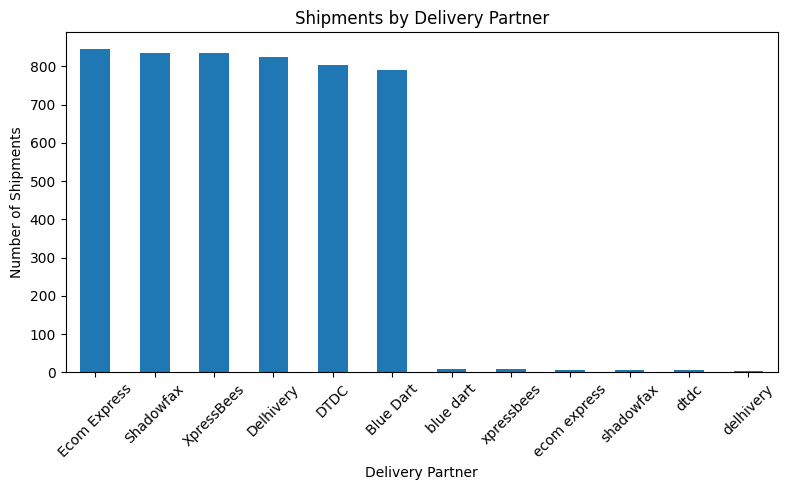

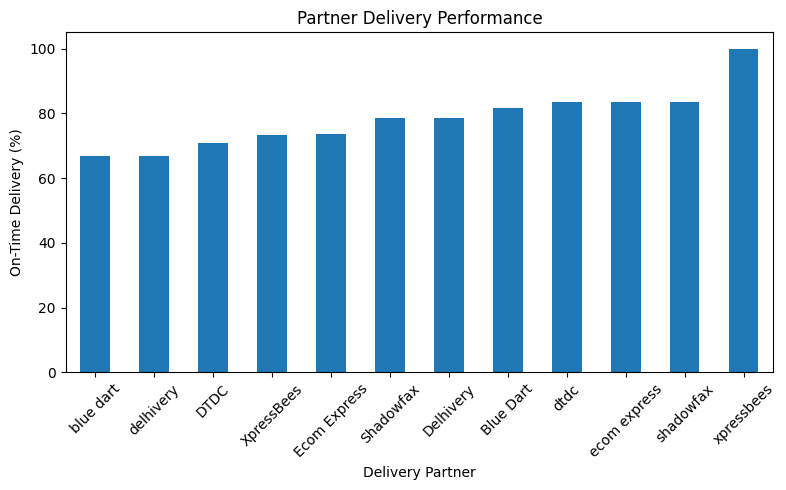

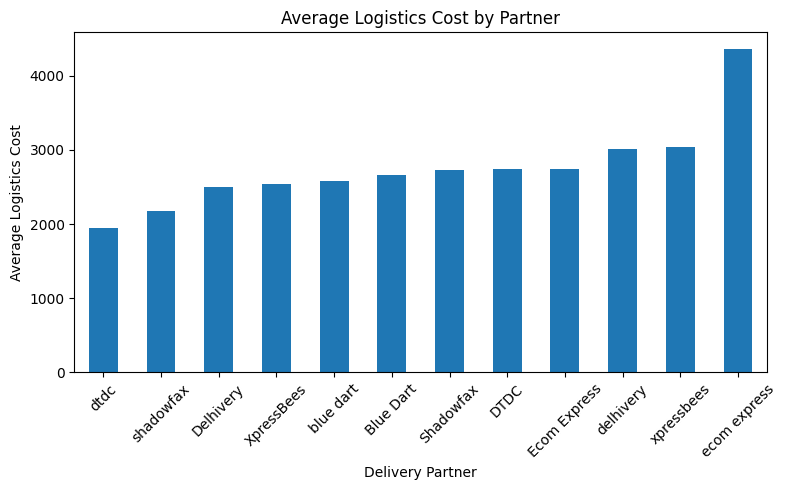

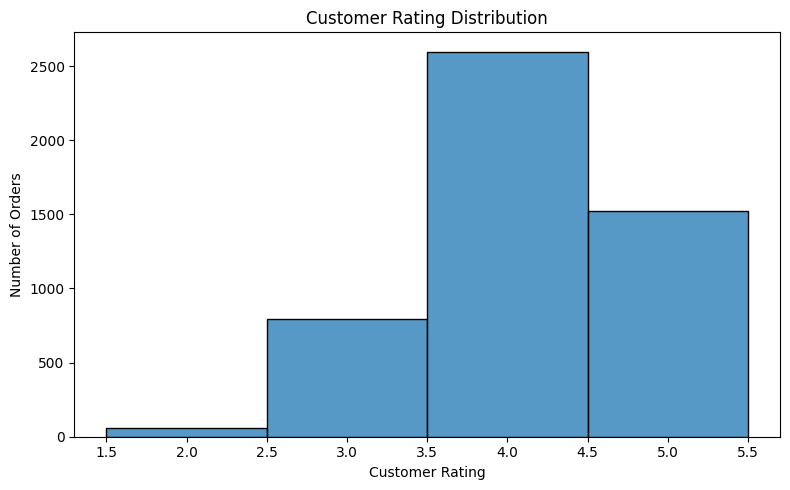

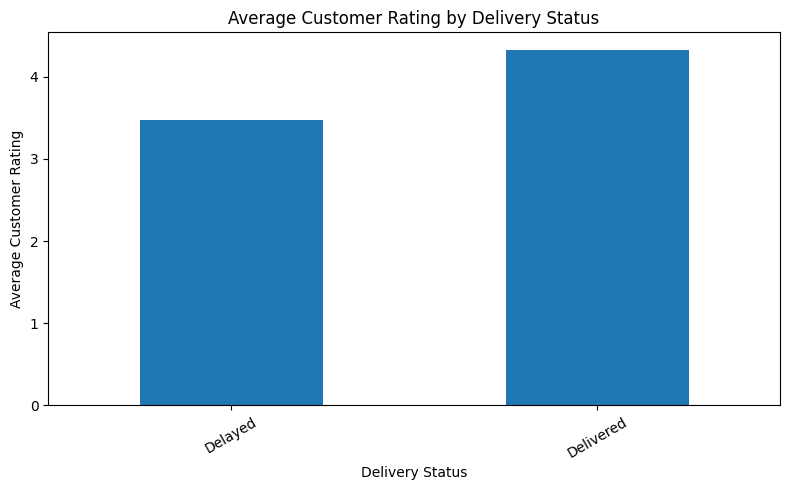

In [38]:
plot_delivery_status(cleaned_df)
plot_monthly_orders(cleaned_df)
plot_monthly_delivery_performance(cleaned_df)

plot_delay_by_warehouse(cleaned_df)
plot_delay_by_shipping_mode(cleaned_df)
plot_delay_by_route(cleaned_df)
plot_delay_distribution(cleaned_df)

plot_cost_by_shipping_mode(cleaned_df)
plot_cost_by_route(cleaned_df)
plot_cost_trend(cleaned_df)

plot_orders_by_warehouse(cleaned_df)
plot_processing_time_by_warehouse(cleaned_df)

plot_shipments_by_partner(cleaned_df)
plot_partner_delivery_performance(cleaned_df)
plot_partner_cost(cleaned_df)

plot_customer_rating_distribution(cleaned_df)
plot_rating_by_delivery_status(cleaned_df)

# 12. Business Insights

The following insights are based on the KPI analysis, business analysis,
EDA, and visualizations.

## Delivery Performance

The analysis shows the overall number of orders, delivered orders,
delayed orders, on-time delivery percentage, average delivery time,
and average delay.

## Route Performance

Route analysis shows differences in shipment volume, delivery delays,
and logistics costs across routes.

Routes with higher delay or cost require further operational review.

## Warehouse Performance

Warehouse analysis shows differences in order volume, processing time,
and delivery delay.

Warehouses with higher processing time or delay require further
investigation into operational processes.

## Transportation Performance

Shipping mode analysis shows differences in usage, cost, delivery
time, and delay performance.

## Delivery Partner Performance

Delivery partner analysis shows differences in shipment volume,
on-time performance, cost, and damage rate.

## Cost Performance

The analysis provides visibility into shipping cost, fuel cost,
total logistics cost, average logistics cost, and cost differences
across routes, warehouses, shipping modes, and delivery partners.

## Customer Experience

Customer ratings, returns, and damaged shipments provide indicators
of customer experience and shipment quality.

### Finding

The analysis shows that ______ has the highest average delay among
the warehouses analyzed.

### Business Meaning

This indicates that this warehouse may require further investigation
into processing and dispatch operations.

### Recommendation

The operations team should review processing time, workload,
dispatch procedures, and shipment handoff activities.


# 13. Recommendations

Based on the findings from the analysis, the following operational
recommendations can be considered:

1. Review routes with consistently high delivery delays.

2. Investigate warehouses with high processing time or high delay
   percentages.

3. Review shipping modes with relatively high logistics costs or
   delivery delays.

4. Monitor delivery partner performance using shipment volume,
   on-time delivery, cost, and damage metrics.

5. Investigate damaged and returned shipments to understand possible
   operational causes.

6. Monitor customer ratings together with delivery status to identify
   areas requiring further investigation.

7. Monitor logistics cost trends and investigate significant changes
   in route, warehouse, shipping mode, or partner costs.

8. Use the KPI dashboard to continuously monitor delivery performance
   and logistics cost.

# 14. Final Conclusion

## Conclusion

The Logistics Delivery Performance & Cost Analytics project provides
a structured analysis of logistics operations using order, route,
warehouse, transportation, delivery partner, cost, customer rating,
damage, and return data.

The project includes data loading, data quality assessment, data
cleaning, derived business metrics, exploratory data analysis,
KPI analysis, business analysis, and visualization.

The analysis provides visibility into delivery performance, delays,
route efficiency, warehouse operations, transportation modes,
delivery partner performance, logistics costs, and customer experience.

The results can help management identify operational areas that
require further investigation and support data-supported logistics
decisions.

The final dashboard and business report provide a consolidated view
of the analytical results and recommendations.